# Sherlock Holmes: recuperar uma passagem também exige reconhecer os limites da busca

Como encontrar informação em nove obras quando a pergunta usa palavras diferentes do texto?
Comparamos **busca literal, TF-IDF e BM25**, recuperando até cinco parágrafos por consulta e conservando arquivo e linhas para conferência.

Neste conjunto, BM25 encontrou uma referência conhecida em **12/18 consultas positivas**, TF-IDF em **10/18** e busca literal em **6/18**.
TF-IDF e BM25 também devolveram resultados nas **seis consultas sem resposta**, enquanto a busca literal não devolveu nenhum.
A questão central é entender esse ganho de recuperação junto de sua limitação: **um trecho relacionado pode não responder à pergunta**.

O percurso é conhecer o acervo, entender os métodos, comparar o mesmo teste e examinar seus erros.
A ferramenta recupera referências documentais; não inclui chatbot nem geração de respostas por LLM.

*English summary:* This notebook compares literal, TF-IDF and BM25 retrieval over nine Sherlock Holmes works.
On 18 positive queries, known-reference hits in the top five were 6, 10 and 12, respectively.
TF-IDF and BM25 returned passages for all six unanswerable queries; literal retrieval returned none.
The small, curated benchmark measures known-reference retrieval, not general accuracy or reliable answerability detection.


## 1. Preparar a análise no Kaggle

1. Anexe o dataset [Sherlock Holmes Series](https://www.kaggle.com/datasets/talesgomes27/sherleck-books).
2. Habilite **Internet** para instalar as ferramentas e o ambiente Python.
3. Execute as células na ordem.

O código necessário está incluído neste notebook. Os TXT do dataset são apenas lidos; as saídas ficam em `/kaggle/working/sherlock_analysis_v2`.
O processamento usa um ambiente Python separado. Os gráficos usam as bibliotecas do kernel, sem modificar as dependências dos métodos de busca.


In [1]:
import base64
import hashlib
import io
import json
import os
from pathlib import Path, PurePosixPath
import stat
import subprocess
import sys
import zipfile
from IPython.display import display, Markdown

WORK_DIR = Path(os.environ.get("SHERLOCK_NOTEBOOK_WORK_DIR", "/kaggle/working/sherlock_analysis_v2")).expanduser().resolve()
local_raw = os.environ.get("SHERLOCK_RAW_DIR")
if local_raw:
    RAW_DIR = Path(local_raw).expanduser().resolve()
else:
    candidates = list(Path("/kaggle/input").rglob("a_study_in_scarlet.txt"))
    if len(candidates) != 1:
        raise RuntimeError("Anexe uma única cópia do dataset Sherlock Holmes Series antes de executar.")
    RAW_DIR = candidates[0].parent.resolve()
if not RAW_DIR.is_dir():
    raise ValueError("A pasta do dataset não foi encontrada.")
if WORK_DIR.is_relative_to(RAW_DIR) or RAW_DIR.is_relative_to(WORK_DIR):
    raise ValueError("Use pastas separadas para o dataset e as saídas.")
WORK_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_DIR = WORK_DIR / "analysis"
REPORT_PATH = WORK_DIR / "search_results.json"

def run_quiet(command, *, cwd=None, env=None):
    result = subprocess.run(command, cwd=cwd, env=env, text=True, capture_output=True)
    if result.returncode:
        details = (result.stdout + "\n" + result.stderr).replace(str(WORK_DIR), "<workspace>").replace(str(RAW_DIR), "<dataset>")
        details = details.replace(str(Path.home()), "<home>")
        raise RuntimeError(f"Falha ao preparar ou executar a análise:\n{details[-5000:]}")
    return result

print("Dataset localizado. A análise verificará os arquivos antes de calcular os resultados.")


Dataset localizado. A análise verificará os arquivos antes de calcular os resultados.


In [2]:
BUNDLE_B64 = "..."
BUNDLE_SHA256 = "90576f75103e2d999328c7a2afb08384a5009877ff5f7d19ae076401c0569547"
# END EMBEDDED PAYLOAD

payload = base64.b64decode(BUNDLE_B64, validate=True)
if hashlib.sha256(payload).hexdigest() != BUNDLE_SHA256:
    raise ValueError("Código incluído no notebook está incompleto ou foi alterado.")
if SOURCE_DIR.is_symlink():
    raise ValueError("Use uma pasta de saída sem links simbólicos.")
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    members = archive.infolist()
    names = set()
    if not members:
        raise ValueError("O código incluído está vazio.")
    for member in members:
        relative = PurePosixPath(member.filename)
        mode = member.external_attr >> 16
        if (relative.is_absolute() or ".." in relative.parts or "\\" in member.filename
                or relative.as_posix() != member.filename or member.is_dir()
                or stat.S_IFMT(mode) not in (0, stat.S_IFREG) or member.filename in names):
            raise ValueError("Caminho ou tipo inválido no código incluído.")
        names.add(member.filename)
        target = SOURCE_DIR.joinpath(*relative.parts)
        if any(path.is_symlink() for path in [target, *target.parents] if path.is_relative_to(SOURCE_DIR)):
            raise ValueError("Links simbólicos não são permitidos na pasta da análise.")
        if not target.resolve().is_relative_to(SOURCE_DIR.resolve()):
            raise ValueError("Caminho fora da pasta da análise.")
        content = archive.read(member)
        if target.exists():
            if not target.is_file() or target.read_bytes() != content:
                raise ValueError("Código existente diverge desta análise; use uma nova pasta de saída.")
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(content)
print("Código da análise conferido e disponível localmente.")


Código da análise conferido e disponível localmente.


In [3]:
UV_VERSION = "0.13.5"
probe = subprocess.run([sys.executable, "-m", "uv", "--version"], text=True, capture_output=True)
if probe.returncode or probe.stdout.strip().split()[1:2] != [UV_VERSION]:
    run_quiet([sys.executable, "-m", "pip", "install", f"uv=={UV_VERSION}"])
try:
    import matplotlib
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    run_quiet([sys.executable, "-m", "pip", "install", "matplotlib==3.11.2"])
    import matplotlib
    import matplotlib.pyplot as plt

UV_ENV = os.environ.copy()
UV_ENV.pop("VIRTUAL_ENV", None)
UV_ENV.pop("UV_PROJECT_ENVIRONMENT", None)
UV_ENV["UV_CACHE_DIR"] = str(WORK_DIR / "cache")
UV_ENV["UV_PYTHON_INSTALL_DIR"] = str(WORK_DIR / "python")
run_quiet([sys.executable, "-m", "uv", "sync", "--managed-python", "--python", "3.11.17", "--frozen"],
          cwd=SOURCE_DIR, env=UV_ENV)
EXECUTION_PATH = SOURCE_DIR / "reports/v2/notebook_execution.json"
run_quiet([sys.executable, "-m", "uv", "run", "--managed-python", "--python", "3.11.17", "--frozen",
           "python", "-m", "sherlock_search.v2_final", "--root", str(SOURCE_DIR),
           "--raw-dir", str(RAW_DIR), "--output", str(EXECUTION_PATH)], cwd=SOURCE_DIR, env=UV_ENV)
reference_bytes = (SOURCE_DIR / "reports/v2/final.json").read_bytes()
execution_bytes = EXECUTION_PATH.read_bytes()
if execution_bytes != reference_bytes:
    raise ValueError("A execução diverge do resultado de referência; confira os dados e o ambiente.")
if REPORT_PATH.is_symlink() or (REPORT_PATH.exists() and (not REPORT_PATH.is_file() or REPORT_PATH.stat().st_nlink > 1)):
    raise ValueError("O relatório de saída deve ser um arquivo próprio.")
REPORT_PATH.write_bytes(execution_bytes)
report = json.loads(execution_bytes)
assert report["query_count"] == 24 and len(report["results"]) == 24
assert report["counts"]["answerable"] == 18 and report["counts"]["unanswerable"] == 6
assert report["corpus_totals"]["files"] == 9
assert [report["methods"][key]["positive_hits"] for key in ("literal_v1", "tfidf_v1", "bm25")] == [6, 10, 12]
assert [report["methods"][key]["false_positive_queries"] for key in ("literal_v1", "tfidf_v1", "bm25")] == [0, 6, 6]
print("Análise reproduzida: 9 obras e 24 consultas. O JSON coincide byte a byte com a referência publicada.")


Análise reproduzida: 9 obras e 24 consultas. O JSON coincide byte a byte com a referência publicada.


## 2. Quanto texto há no acervo?

Os nove arquivos em inglês contêm romances e coletâneas de Arthur Conan Doyle.
A preparação lê UTF-8 com BOM, normaliza quebras de linha em memória e aplica recortes editoriais revisados para retirar cabeçalhos e rodapés.
Cada parágrafo mantém o nome do arquivo e as linhas originais, numeradas a partir de 1.
A contagem de palavras usa letras Unicode, aceitando apóstrofo ou hífen interno e excluindo números.

O gráfico representa **volume de texto retido**, sem medir qualidade literária ou desempenho por obra.


In [4]:
def number(value):
    return f"{value:,}".replace(",", ".")

def table(headers, rows):
    def escape(value):
        return str(value).replace("|", r"\|").replace("\n", " ")
    lines = ["| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(escape(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

corpus = json.loads((SOURCE_DIR / "reports/m1_quality.json").read_text(encoding="utf-8"))
assert corpus["totals"] == report["corpus_totals"] and len(corpus["files"]) == 9
totals = corpus["totals"]
books = sorted(corpus["files"], key=lambda book: book["retained_words"], reverse=True)
display(Markdown(f"**{totals['files']} obras · {number(totals['retained_words'])} palavras retidas · "
                 f"{number(totals['paragraphs'])} parágrafos**\n\n"
                 f"Os recortes excluíram {number(totals['removed_words'])} palavras dos originais."))
table(["Obra", "Palavras retidas", "Parágrafos"],
      [(book["title"], number(book["retained_words"]), number(book["paragraphs"])) for book in books])


**9 obras · 656.884 palavras retidas · 15.598 parágrafos**

Os recortes excluíram 29.566 palavras dos originais.

| Obra | Palavras retidas | Parágrafos |
| --- | --- | --- |
| The Return of Sherlock Holmes | 112.364 | 2.573 |
| The Adventures of Sherlock Holmes | 104.454 | 2.540 |
| The Memoirs of Sherlock Holmes | 95.549 | 2.191 |
| The Case-Book of Sherlock Holmes | 82.179 | 2.247 |
| The Hound of the Baskervilles | 59.225 | 1.483 |
| His Last Bow | 58.982 | 1.424 |
| The Valley of Fear | 57.690 | 1.551 |
| A Study in Scarlet | 43.334 | 805 |
| The Sign of the Four | 43.107 | 784 |

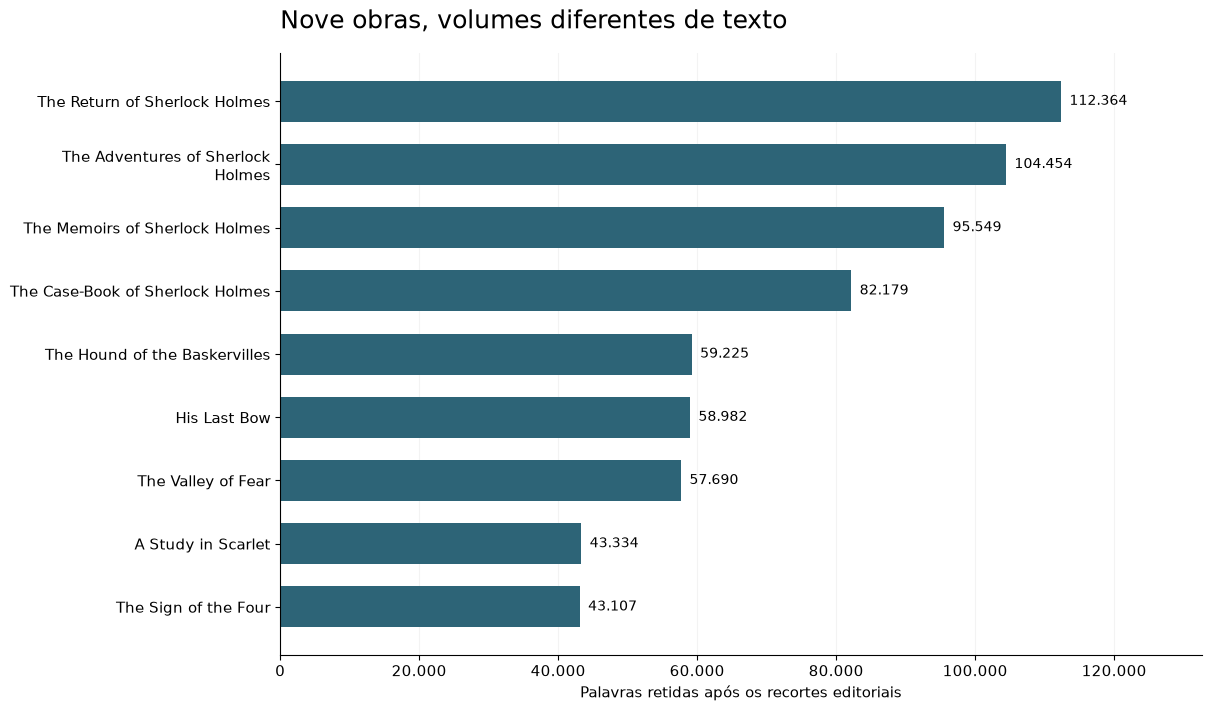

In [5]:
from textwrap import fill
from matplotlib.ticker import FuncFormatter, PercentFormatter

FIGURE_DIR = WORK_DIR / "figures"
if FIGURE_DIR.is_symlink():
    raise ValueError("A pasta de figuras não pode ser um link simbólico.")
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def export_figure(fig, name):
    for extension in ("png", "svg"):
        output = FIGURE_DIR / f"{name}.{extension}"
        if output.is_symlink() or (output.exists() and (not output.is_file() or output.stat().st_nlink > 1)):
            raise ValueError("A figura de saída deve ser um arquivo próprio.")
        fig.savefig(output, dpi=160, bbox_inches="tight", facecolor="white")
    svg = FIGURE_DIR / f"{name}.svg"
    svg.write_text("\n".join(line.rstrip() for line in svg.read_text(encoding="utf-8").splitlines()) + "\n", encoding="utf-8")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
values = [book["retained_words"] for book in books]
bars = ax.barh([fill(book["title"], 32) for book in books], values, color="#2D6477", height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, labels=[number(value) for value in values], padding=6, fontsize=10)
ax.set_xlim(0, max(values) * 1.18)
ax.set_xlabel("Palavras retidas após os recortes editoriais")
ax.set_title("Nove obras, volumes diferentes de texto", loc="left", fontsize=18, pad=18)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: number(int(value))))
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
export_figure(fig, "corpus_size")


## 3. Três formas de recuperar parágrafos

| Método | Representação e ordenação |
|---|---|
| Literal | Procura a expressão inteira sem distinguir maiúsculas e minúsculas e ordena pela contagem de ocorrências. |
| TF-IDF | Pondera palavras, remove stopwords em inglês e ordena pela similaridade de cosseno. |
| BM25 | Pondera termos pela raridade, limita o efeito da repetição e ajusta pelo comprimento do parágrafo. |

Os métodos usam os mesmos parágrafos e retornam no máximo cinco resultados. TF-IDF e BM25 retornam apenas scores positivos.
São métodos lexicais: nenhum interpreta uma pergunta como um modelo de linguagem.
Um score positivo indica correspondência de termos, **não probabilidade de haver resposta**. As escalas de TF-IDF, BM25 e contagem literal não são comparáveis entre si.

A configuração foi definida usando **36 consultas de desenvolvimento** (27 positivas e nove negativas), antes das 24 consultas finais.
Literal e TF-IDF mantêm a configuração anterior; BM25 usa **k1 = 1,2, b = 0,75 e min_score = 0,0**.
O corte BM25 candidato **32** foi rejeitado no desenvolvimento porque eliminou todos os **12 acertos positivos**, embora reduzisse os retornos negativos de 9/9 para 3/9.
Manter o ranking sem corte adicional preservou a recuperação, mas deixou a abstenção como problema aberto.
Este notebook reproduz a configuração definida: não executa novas grades nem ajusta parâmetros com as consultas finais.

O teste final tem **18 consultas positivas** (seis expressões exatas, seis paráfrases e seis de contexto) e **seis negativas**.
Os três métodos são comparados nesse mesmo conjunto; os percentuais não são comparados diretamente aos de testes anteriores com outros denominadores.

- **Consultas positivas com referência conhecida no top 5:** uma consulta conta uma vez se pelo menos um dos cinco resultados coincide com uma referência anotada. Maior é melhor.
- **Consultas negativas com retorno:** uma consulta conta uma vez se algum parágrafo é devolvido, mesmo sem responder ao detalhe pedido. Menor é melhor.
- **MRR@5 nas positivas:** média do inverso da posição da primeira referência conhecida, com zero quando ela não aparece no top 5. Maior é melhor.

Os denominadores são consultas, não IDs de parágrafos únicos. Os julgamentos conhecidos não esgotam todos os trechos possivelmente relevantes.


| Método | Positivas com referência no top 5 (18) | Negativas com retorno (6) | MRR@5 positivas |
| --- | --- | --- | --- |
| Literal | 6/18 (33.3%) | 0/6 (0%) | 0.2963 |
| TF-IDF | 10/18 (55.6%) | 6/6 (100%) | 0.3981 |
| BM25 | 12/18 (66.7%) | 6/6 (100%) | 0.4907 |

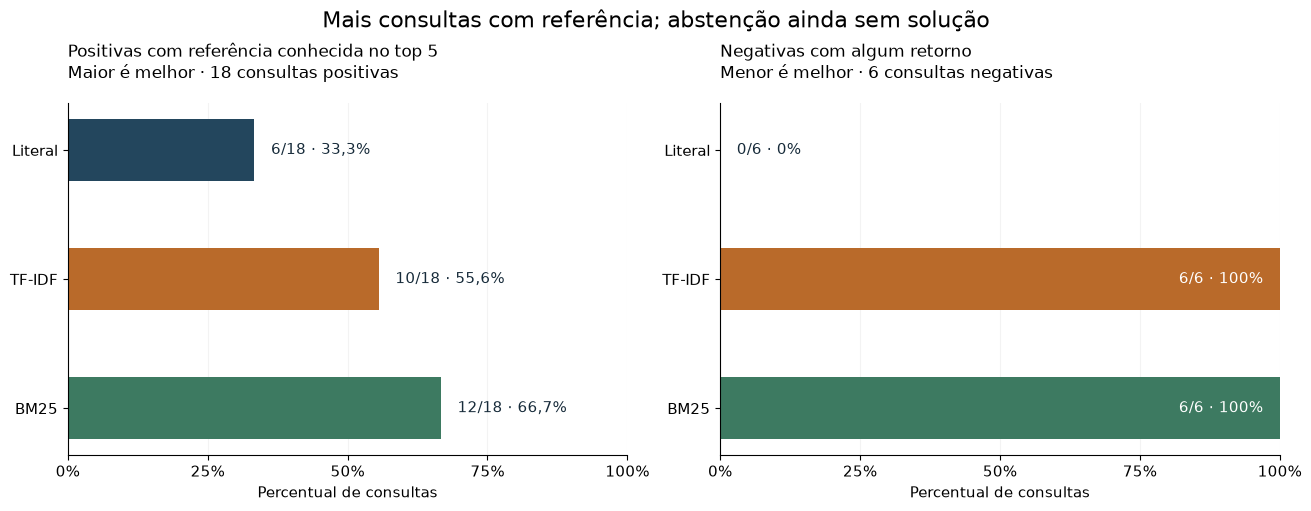

In [6]:
methods = [("literal_v1", "Literal", "#23465D"), ("tfidf_v1", "TF-IDF", "#B96A2A"), ("bm25", "BM25", "#3D7A61")]
table(["Método", "Positivas com referência no top 5 (18)", "Negativas com retorno (6)", "MRR@5 positivas"],
      [(label, f"{report['methods'][key]['positive_hits']}/18 ({report['methods'][key]['known_hit_at_5']:.1%})",
        f"{report['methods'][key]['false_positive_queries']}/6 ({report['methods'][key]['false_positive_rate']:.0%})",
        f"{report['methods'][key]['mrr_at_5']:.4f}") for key, label, color in methods])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
panels = [("known_hit_at_5", "positive_hits", "positive_queries", "Positivas com referência conhecida no top 5", "Maior é melhor · 18 consultas positivas"),
          ("false_positive_rate", "false_positive_queries", "negative_queries", "Negativas com algum retorno", "Menor é melhor · 6 consultas negativas")]
for ax, (metric, count, denominator, title, subtitle) in zip(axes, panels):
    rates = [report["methods"][key][metric] for key, label, color in methods]
    bars = ax.barh([label for key, label, color in methods], rates,
                   color=[color for key, label, color in methods], height=0.48)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(title + "\n" + subtitle, loc="left", fontsize=12, pad=18)
    ax.set_xlabel("Percentual de consultas")
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    for bar, (key, label, color), rate in zip(bars, methods, rates):
        metrics = report["methods"][key]
        text = f"{metrics[count]}/{metrics[denominator]} · {rate:.1%}".replace(".0%", "%").replace(".", ",")
        inside = rate >= 0.85
        ax.text(rate - 0.03 if inside else rate + 0.03, bar.get_y() + bar.get_height()/2, text,
                va="center", ha="right" if inside else "left", color="white" if inside else "#172B3A", fontsize=11)
fig.suptitle("Mais consultas com referência; abstenção ainda sem solução", fontsize=16)
export_figure(fig, "final_comparison")


## 4. Onde os métodos acertam e onde falham?

BM25 encontrou referência conhecida em **duas consultas a mais que TF-IDF** neste teste e teve MRR@5 maior.
Os dois, porém, retornaram trechos em **6/6 negativas**. A busca literal encontrou menos referências conhecidas e devolveu **0/6** retornos nas negativas.
Esses resultados não demonstram superioridade geral de um método nem acurácia geral de uma aplicação.

Na tabela das positivas, **sim** indica uma referência conhecida no top 5; **não** indica apenas que ela não apareceu.
Um hit pode ser evidência parcial e não sustentar todas as partes de uma pergunta de contexto.
As consultas originais são mantidas em inglês para permitir conferir o que foi efetivamente buscado.


In [7]:
queries = json.loads((SOURCE_DIR / "data/processed/v2_holdout/final.json").read_text(encoding="utf-8"))
query_by_id = {query["id"]: query for query in queries}
assert len(query_by_id) == 24 and set(query_by_id) == {item["id"] for item in report["results"]}
type_labels = {"exact": "Expressão exata", "paraphrase": "Paráfrase", "context": "Contexto"}
positive_rows, negative_rows, negative_top_rows = [], [], []
for item in report["results"]:
    query = query_by_id[item["id"]]
    assert query["answerable"] == item["answerable"]
    if item["answerable"]:
        known = set(item["known_relevant_ids"])
        hits = ["sim" if any(row["id"] in known for row in item[key][:5]) else "não" for key, label, color in methods]
        positive_rows.append((item["id"], query["query"], type_labels[query["query_type"]], *hits))
    else:
        negative_rows.append((item["id"], query["query"], *(len(item[key]) for key, label, color in methods)))
        top = []
        for key in ("tfidf_v1", "bm25"):
            first = item[key][0] if item[key] else None
            top.extend((first["id"], f"{first['score']:.6f}") if first else ("—", "—"))
        negative_top_rows.append((item["id"], *top))
assert len(positive_rows) == 18 and len(negative_rows) == 6
display(Markdown("### 18 consultas positivas: uma referência conhecida apareceu no top 5?"))
table(["ID", "Consulta original", "Tipo", "Literal", "TF-IDF", "BM25"], positive_rows)
display(Markdown("### Seis consultas negativas: quantos parágrafos foram retornados?"))
table(["ID", "Consulta original", "Literal", "TF-IDF", "BM25"], negative_rows)
display(Markdown("### Primeiro resultado nas negativas: origem e score"))
table(["ID", "TF-IDF: ID do top 1", "TF-IDF: score", "BM25: ID do top 1", "BM25: score"], negative_top_rows)


### 18 consultas positivas: uma referência conhecida apareceu no top 5?

| ID | Consulta original | Tipo | Literal | TF-IDF | BM25 |
| --- | --- | --- | --- | --- | --- |
| v2-final-01 | a mule and two horses waiting in the Eagle Ravine | Expressão exata | sim | sim | sim |
| v2-final-02 | Why did Jefferson Hope propose leaving the Ferrier house through a side window and crossing the fields that night? | Contexto | não | não | sim |
| v2-final-03 | Why so large a coffin for so small a body? | Expressão exata | sim | não | sim |
| v2-final-04 | How did the uneven mud marks on Watson's coat tell Holmes that Watson had shared a cab? | Paráfrase | não | não | não |
| v2-final-05 | What two things did Victor Hatherley have to change at Reading before catching the last train to Eyford? | Paráfrase | não | sim | sim |
| v2-final-06 | What did Holmes discover about the bell-rope in Helen Stoner's room that made its apparent purpose doubtful? | Contexto | não | não | não |
| v2-final-07 | Weekly reports will oblige | Expressão exata | sim | sim | sim |
| v2-final-08 | Why did Bennett object to calling an outside surgeon after Professor Presbury's throat had been treated? | Contexto | não | sim | não |
| v2-final-09 | in the character of a free woman | Expressão exata | sim | sim | sim |
| v2-final-10 | Who was the bearded man whose body Holmes and Watson initially mistook for Sir Henry on the moor? | Paráfrase | não | não | não |
| v2-final-11 | Why had the captors covered the Greek prisoner's face with strips of plaster? | Paráfrase | não | não | não |
| v2-final-12 | How did Holmes's interpretation of the two Englishmen's deaths differ from the Hungarian police opinion reported in the newspaper cutting? | Contexto | não | sim | sim |
| v2-final-13 | golden pince-nez | Expressão exata | sim | sim | sim |
| v2-final-14 | Why did Holmes connect the clay left in the tutor's room with the university jumping-pit when reconstructing Gilchrist's movements? | Contexto | não | sim | sim |
| v2-final-15 | Benares metal-work | Expressão exata | sim | sim | sim |
| v2-final-16 | Why did Athelney Jones abandon his case against Thaddeus Sholto? | Paráfrase | não | não | não |
| v2-final-17 | Why did Brother Morris warn that attacking James Stanger could turn the whole district against the lodge? | Paráfrase | não | sim | sim |
| v2-final-18 | What precautions by the Crow Hill attackers help explain why no witness could swear to their identities despite the crowd of miners? | Contexto | não | não | sim |

### Seis consultas negativas: quantos parágrafos foram retornados?

| ID | Consulta original | Literal | TF-IDF | BM25 |
| --- | --- | --- | --- | --- |
| v2-final-19 | What were the ages of the two horses Jefferson Hope had waiting in the Eagle Ravine? | 0 | 5 | 5 |
| v2-final-20 | What price did Stimson and Co. charge for the specially enlarged coffin delivered to Poultney Square? | 0 | 5 | 5 |
| v2-final-21 | What was the railway fare for Victor Hatherley's journey from Reading to Eyford? | 0 | 5 | 5 |
| v2-final-22 | What was the name of the ship Barrymore expected to take Selden to South America? | 0 | 5 | 5 |
| v2-final-23 | What was the exact weight in pounds of the empty Agra treasure-box Watson opened for Mary Morstan? | 0 | 5 | 5 |
| v2-final-24 | What calibre of ammunition was used to kill the Crow Hill engineer Menzies? | 0 | 5 | 5 |

### Primeiro resultado nas negativas: origem e score

| ID | TF-IDF: ID do top 1 | TF-IDF: score | BM25: ID do top 1 | BM25: score |
| --- | --- | --- | --- | --- |
| v2-final-19 | a_study_in_scarlet.txt:3619-3621 | 0.500125 | a_study_in_scarlet.txt:3619-3621 | 29.116357 |
| v2-final-20 | the_hound_of_the_baskervilles.txt:2821-2821 | 0.320414 | his_last_bow.txt:5127-5129 | 12.880155 |
| v2-final-21 | the_return_of_sherlock_holmes.txt:10682-10682 | 0.315162 | the_adventures_of_sherlock_holmes.txt:7987-7992 | 14.715548 |
| v2-final-22 | the_adventures_of_sherlock_holmes.txt:1768-1768 | 0.373251 | the_return_of_sherlock_holmes.txt:5937-5940 | 13.511485 |
| v2-final-23 | the_adventures_of_sherlock_holmes.txt:10627-10627 | 0.342986 | the_sign_of_the_four.txt:3409-3410 | 16.926443 |
| v2-final-24 | the_valley_of _fear.txt:6063-6063 | 0.324114 | the_valley_of _fear.txt:5804-5809 | 17.273227 |

As negativas pedem detalhes plausíveis sobre personagens e acontecimentos presentes no acervo: idade de cavalos, preço de um caixão, tarifa ferroviária, nome de um navio, peso de uma caixa e calibre de munição.
Nomes e temas compartilhados geram scores positivos mesmo quando o parágrafo não fornece o detalhe solicitado.
Os IDs do top 1 acima ajudam a localizar essas associações; os scores devem ser lidos apenas dentro de cada método.
Por exemplo, no caso da idade dos cavalos, o mesmo parágrafo aparece no top 1 dos dois métodos: ele menciona os cavalos e o local de espera, mas não informa suas idades. A correspondência lexical explica o retorno sem comprovar uma resposta.

Os resultados completos, com até cinco IDs e scores por método, estão no JSON de saída.

As negativas foram rotuladas a partir de contextos inspecionados. Isso não prova ausência formal da informação em todo o acervo.
Também **não retornar nada com a expressão literal não atesta ausência semântica**: uma resposta pode usar outras palavras.
As referências usadas na verificação das negativas são contextos de inspeção, não referências de resposta.

Uma próxima versão pode separar **recuperar candidatos** de **decidir se a evidência é suficiente**. Cobertura dos termos pedidos, margem entre scores e um avaliador de pares pergunta–trecho são sinais a testar em desenvolvimento; nenhum deles garante ausência de resposta. Embeddings também podem recuperar mais texto relacionado sem resolver esse problema. Qualquer configuração nova exigirá outro teste reservado; nenhuma dessas propostas foi ajustada ou avaliada aqui.


## 5. O que este experimento permite concluir?

Neste conjunto, BM25 ampliou a recuperação e melhorou a posição das referências conhecidas em relação ao TF-IDF.
O retorno de trechos nas seis negativas mostra por que uma aplicação de busca precisa permitir conferência da fonte e distinguir proximidade lexical de resposta suficiente.
As medidas descrevem recuperação de referências anotadas, não a correção de respostas geradas.

A amostra é pequena e curada. As referências são não exaustivas e podem oferecer evidência parcial.
As consultas finais foram preparadas por um curador separado, em regiões diferentes das obras usadas no desenvolvimento, com revisão de sobreposição de intenções.
A aprovação foi global, sem comprovação de auditoria humana individual de cada caso.
Essa separação reduz sobreposição direta, mas não elimina dependências narrativas nem sustenta extrapolação para documentos de clientes.

O teste final já foi executado e seus metadados foram publicados. Agora ele serve à reprodução e ao diagnóstico; futuras mudanças exigem **outro ciclo de desenvolvimento e um novo teste independente**.
Abstenção calibrada, busca semântica ou reordenação com cross-encoder são propostas para investigar nesse novo ciclo, ainda não testadas aqui.
Nenhum parâmetro foi alterado a partir dos resultados finais.

**Fonte e créditos:** os TXT do dataset identificam Arthur Conan Doyle e edições do Project Gutenberg.
Os originais preservam seus avisos e créditos. Este notebook apresenta contagens, perguntas e identificadores de linhas, sem republicar os textos das obras.

## 6. Baixar os resultados e conferir a reprodução

O JSON inclui os resultados por consulta, scores, IDs de origem, totais do corpus, parâmetros e versões do processamento.
As duas figuras são exportadas em PNG e SVG. Após salvar uma versão executada, baixe os arquivos na área **Output** do Kaggle, dentro de `sherlock_analysis_v2`.
A execução verifica as versões e os arquivos de entrada e exige que o JSON calculado coincida byte a byte com a referência incluída.


In [8]:
table(["Componente do processamento", "Versão"], list(report["versions"].items()))
table(["Ferramenta de reprodução ou visualização", "Versão"],
      [("uv", UV_VERSION), ("Matplotlib do kernel", matplotlib.__version__)])
files = [(REPORT_PATH.name, "JSON")] + [(f"figures/{name}.{extension}", extension.upper())
        for name in ("corpus_size", "final_comparison") for extension in ("png", "svg")]
assert REPORT_PATH.is_file() and all((WORK_DIR / name).is_file() for name, extension in files)
table(["Arquivo para download", "Formato"], files)
print("Resultados disponíveis na área Output: sherlock_analysis_v2/search_results.json e sherlock_analysis_v2/figures/.")


| Componente do processamento | Versão |
| --- | --- |
| python | 3.11.17 |
| scikit-learn | 1.9.1 |
| numpy | 2.4.6 |
| scipy | 1.17.1 |

| Ferramenta de reprodução ou visualização | Versão |
| --- | --- |
| uv | 0.13.5 |
| Matplotlib do kernel | 3.11.2 |

| Arquivo para download | Formato |
| --- | --- |
| search_results.json | JSON |
| figures/corpus_size.png | PNG |
| figures/corpus_size.svg | SVG |
| figures/final_comparison.png | PNG |
| figures/final_comparison.svg | SVG |

Resultados disponíveis na área Output: sherlock_analysis_v2/search_results.json e sherlock_analysis_v2/figures/.
